# Limpeza de Dados em R - Caderno de Exercício

Bibliotecas úteis

In [1]:
library(repr)
# função para definir dimensão da célula de gráfico no Jupyter:
grafdim <- function (x=11, y=7) { options(repr.plot.width=x,repr.plot.height=y) }

## Base de dados (_dataset_)

O _dataset_ utilizado está disponível no [Kaggle](https://www.kaggle.com) e é a base [kc_house_data](https://www.kaggle.com/datasets/shivachandel/kc-house-data).   
O _dataset_ é composto de dados históricos de casas vendidas entre maio de 2014 e maio de 2015 na cidade de King County, no estado de Washington, EUA. Será utilizada a versão com erros disponível no Moodle.


## Carga

### Obtenção dos dados

In [43]:
kc <- read.csv("dad/kc_house_data.csv", header=TRUE, sep=",")

Avaliando os dados:

In [44]:
summary(kc)

       id                   date           price            bedrooms     
 Min.   :1.000e+06   Length   :21617   Min.   :  75000   Min.   : 0.000  
 1st Qu.:2.123e+09   N.unique :  373   1st Qu.: 321838   1st Qu.: 3.000  
 Median :3.905e+09   N.blank  :    0   Median : 450000   Median : 3.000  
 Mean   :4.581e+09   Min.nchar:   15   Mean   : 540068   Mean   : 3.371  
 3rd Qu.:7.309e+09   Max.nchar:   16   3rd Qu.: 645000   3rd Qu.: 4.000  
 Max.   :9.900e+09                     Max.   :7700000   Max.   :33.000  
                                       NAs    :1         NAs    :1       
   bathrooms      sqft_living       sqft_lot           floors     
 Min.   :0.000   Min.   :  290   Min.   :    520   Min.   :1.000  
 1st Qu.:1.750   1st Qu.: 1424   1st Qu.:   5040   1st Qu.:1.000  
 Median :2.250   Median : 1910   Median :   7618   Median :1.500  
 Mean   :2.115   Mean   : 2080   Mean   :  15106   Mean   :1.494  
 3rd Qu.:2.500   3rd Qu.: 2550   3rd Qu.:  10687   3rd Qu.:2.000  
 Max. 

In [45]:
str(kc)

'data.frame':	21617 obs. of  21 variables:
 $ id           : num  7.13e+09 6.41e+09 5.63e+09 2.49e+09 1.95e+09 ...
 $ date         : chr  "20141013T000000" "20141209T000000" "20150225T000000" "20141209T000000" ...
 $ price        : num  221900 538000 180000 604000 510000 ...
 $ bedrooms     : int  3 3 2 4 3 4 3 3 3 3 ...
 $ bathrooms    : num  1 2.25 1 3 2 4.5 2.25 1.5 1 2.5 ...
 $ sqft_living  : int  1180 2570 770 1960 1680 5420 1715 1060 1780 1890 ...
 $ sqft_lot     : int  5650 7242 10000 5000 8080 101930 6819 9711 7470 6560 ...
 $ floors       : num  1 2 1 1 1 1 2 1 1 2 ...
 $ waterfront   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ view         : int  0 0 0 0 0 0 0 0 0 0 ...
 $ condition    : int  3 3 3 5 3 3 3 3 3 3 ...
 $ grade        : int  7 7 6 7 8 11 7 7 7 7 ...
 $ sqft_above   : int  1180 2170 770 1050 1680 3890 1715 1060 1050 1890 ...
 $ sqft_basement: chr  "0" "400" "0" "910" ...
 $ yr_built     : int  1955 1951 1933 1965 1987 2001 1995 1963 1960 2003 ...
 $ yr_renovated : int  0 1

## Date

In [46]:
print(head(kc))

          id            date   price bedrooms bathrooms sqft_living sqft_lot
1 7129300520 20141013T000000  221900        3      1.00        1180     5650
2 6414100192 20141209T000000  538000        3      2.25        2570     7242
3 5631500400 20150225T000000  180000        2      1.00         770    10000
4 2487200875 20141209T000000  604000        4      3.00        1960     5000
5 1954400510 20150218T000000  510000        3      2.00        1680     8080
6 7237550310 20140512T000000 1225000        4      4.50        5420   101930
  floors waterfront view condition grade sqft_above sqft_basement yr_built
1      1          0    0         3     7       1180             0     1955
2      2          0    0         3     7       2170           400     1951
3      1          0    0         3     6        770             0     1933
4      1          0    0         5     7       1050           910     1965
5      1          0    0         3     8       1680             0     1987
6      1   

In [47]:
unique(substr(kc$date,10,15))

[1] "000000" "e erro"

In [48]:
linha <- grep("erro",kc$date)
kc[linha,]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,⋯,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
,<dbl>,<chr>,<dbl>,<int>,<dbl>,<int>,<int>,<dbl>,<int>,<int>,⋯,<int>,<int>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>
7714,9808640090,duplicate error,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,,NA,NA,NA,NA,NA,NA,NA


In [49]:
kc <- kc[-linha,]

In [50]:
unique(substr(kc$date,10,15))

[1] "000000"

In [51]:
kc$ano <- as.integer(substr(kc$date,1,4))
kc$mes <- as.integer(substr(kc$date,5,6))
kc$dia <- as.integer(substr(kc$date,7,8))

In [53]:
summary(kc$ano)
summary(kc$mes)
summary(kc$dia)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   2014    2014    2014    2014    2015    2015 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.000   4.000   6.000   6.575   9.000  12.000 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   1.00    8.00   16.00   15.69   23.00   31.00 

In [54]:
kc$date <- as.Date(kc$date,tryFormats = c("%Y%m%d"))

In [55]:
print(summary(kc$date))

        Min.      1st Qu.       Median         Mean      3rd Qu.         Max. 
"2014-05-02" "2014-07-22" "2014-10-16" "2014-10-29" "2015-02-17" "2015-05-27" 


In [56]:
summary(kc)

       id                 date                price            bedrooms     
 Min.   :1.000e+06   Min.   :2014-05-02   Min.   :  75000   Min.   : 0.000  
 1st Qu.:2.123e+09   1st Qu.:2014-07-22   1st Qu.: 321838   1st Qu.: 3.000  
 Median :3.905e+09   Median :2014-10-16   Median : 450000   Median : 3.000  
 Mean   :4.580e+09   Mean   :2014-10-29   Mean   : 540068   Mean   : 3.371  
 3rd Qu.:7.309e+09   3rd Qu.:2015-02-17   3rd Qu.: 645000   3rd Qu.: 4.000  
 Max.   :9.900e+09   Max.   :2015-05-27   Max.   :7700000   Max.   :33.000  
                                                                            
   bathrooms      sqft_living       sqft_lot           floors     
 Min.   :0.000   Min.   :  290   Min.   :    520   Min.   :1.000  
 1st Qu.:1.750   1st Qu.: 1424   1st Qu.:   5040   1st Qu.:1.000  
 Median :2.250   Median : 1910   Median :   7618   Median :1.500  
 Mean   :2.115   Mean   : 2080   Mean   :  15106   Mean   :1.494  
 3rd Qu.:2.500   3rd Qu.: 2550   3rd Qu.:  10687 

### Price

In [57]:
summary(kc$price)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  75000  321838  450000  540068  645000 7700000 

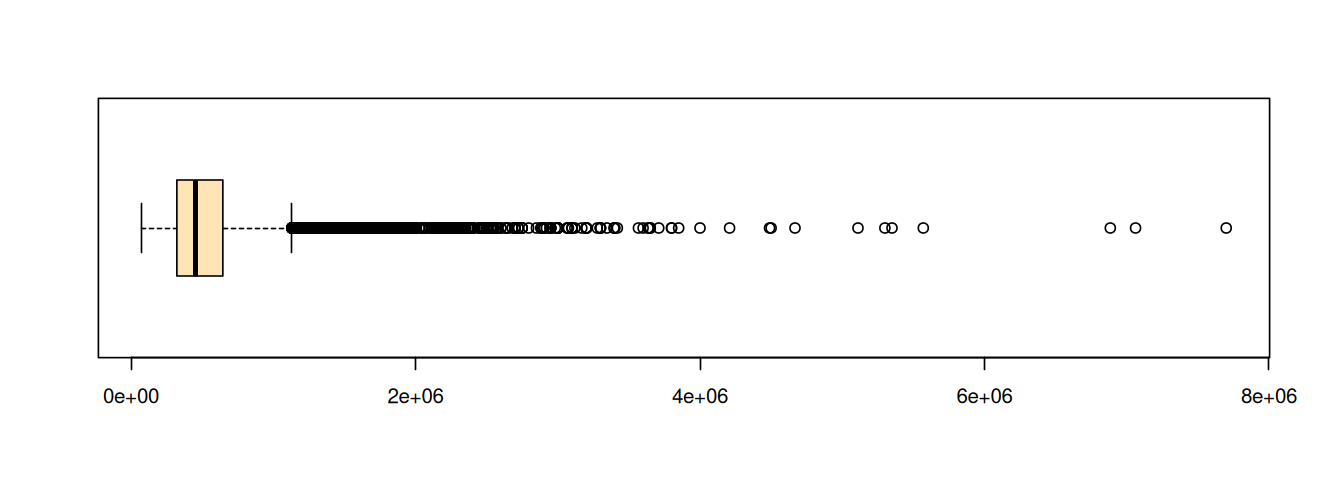

In [59]:
grafdim(11,4)
boxplot(kc$price, horizontal=TRUE, col="moccasin")

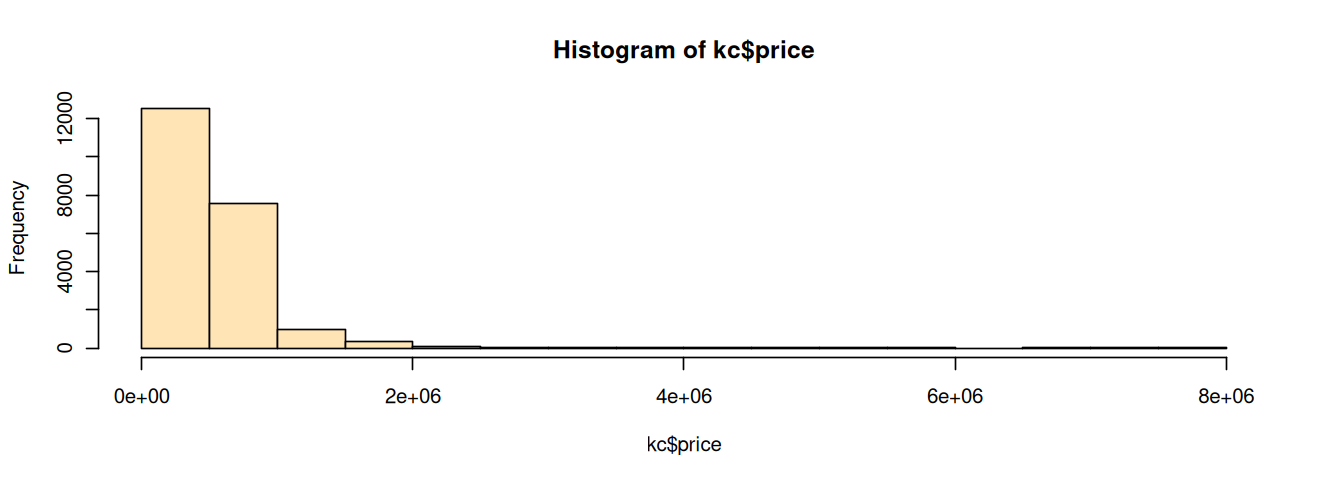

In [60]:
hist(kc$price,col="moccasin")

In [61]:
kc[kc$price > 6000000,]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,⋯,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,ano,mes,dia
,<dbl>,<date>,<dbl>,<int>,<dbl>,<int>,<int>,<dbl>,<int>,<int>,⋯,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>
3916,9808700762,2014-06-11,7062500,5,4.50,10040,37325,2.0,1,2,⋯,1940,2001,98004,47.6500,-122.214,3930,25449,2014,6,11
7254,6762700020,2014-10-13,7700000,6,8.00,12050,27600,2.5,0,3,⋯,1910,1987,98102,47.6298,-122.323,3940,8800,2014,10,13
9257,9208900037,2014-09-19,6885000,6,7.75,9890,31374,2.0,0,4,⋯,2001,0,98039,47.6305,-122.240,4540,42730,2014,9,19


### Bedrooms

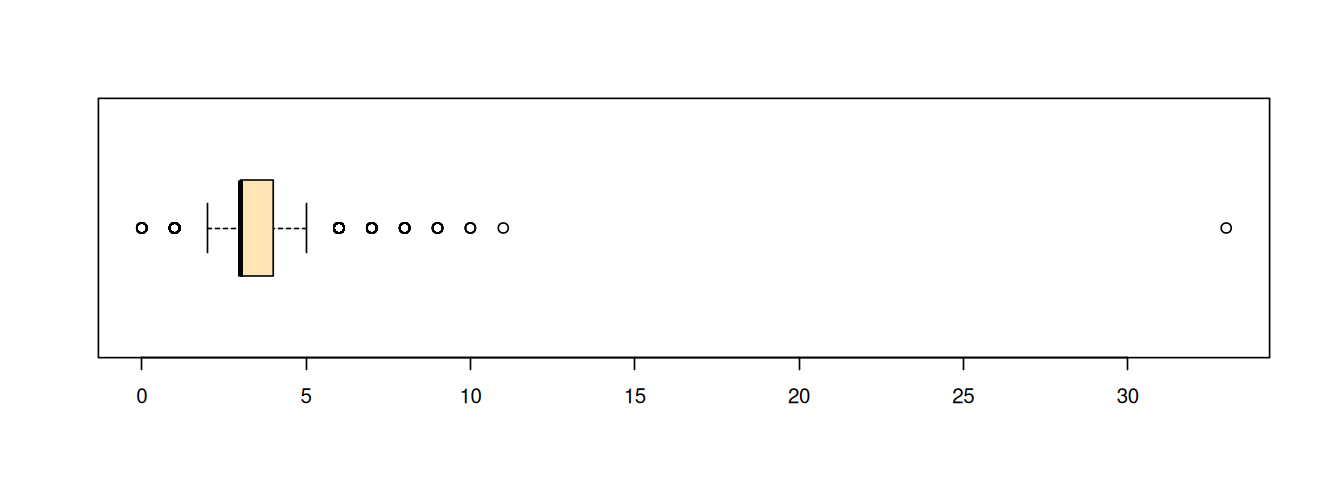

In [62]:
grafdim(11,4)
boxplot(kc$bedrooms, horizontal=TRUE, col="moccasin")

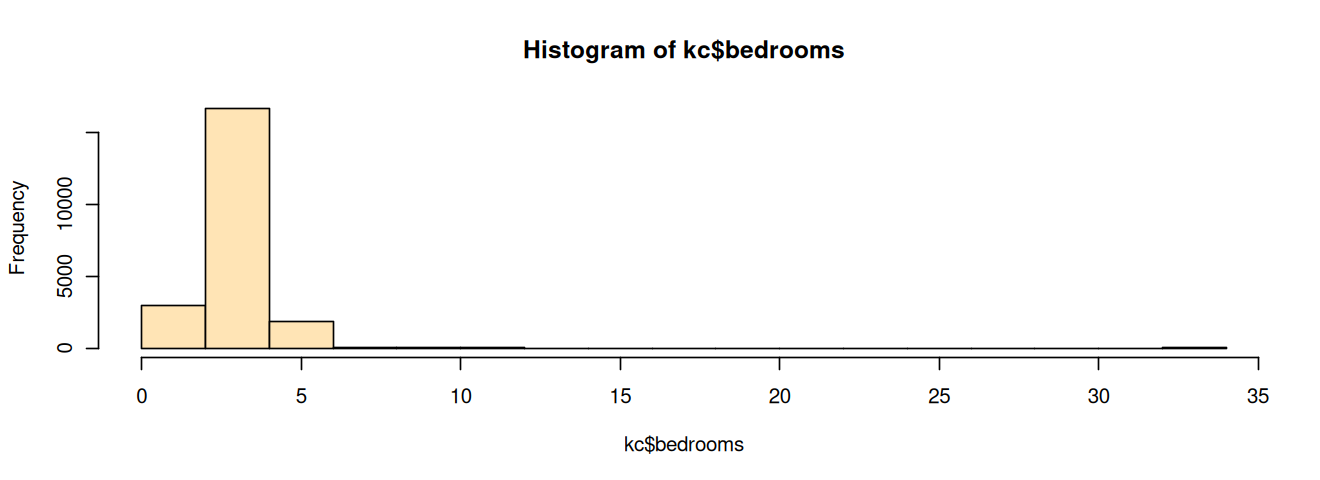

In [63]:
hist(kc$bedrooms,col="moccasin")

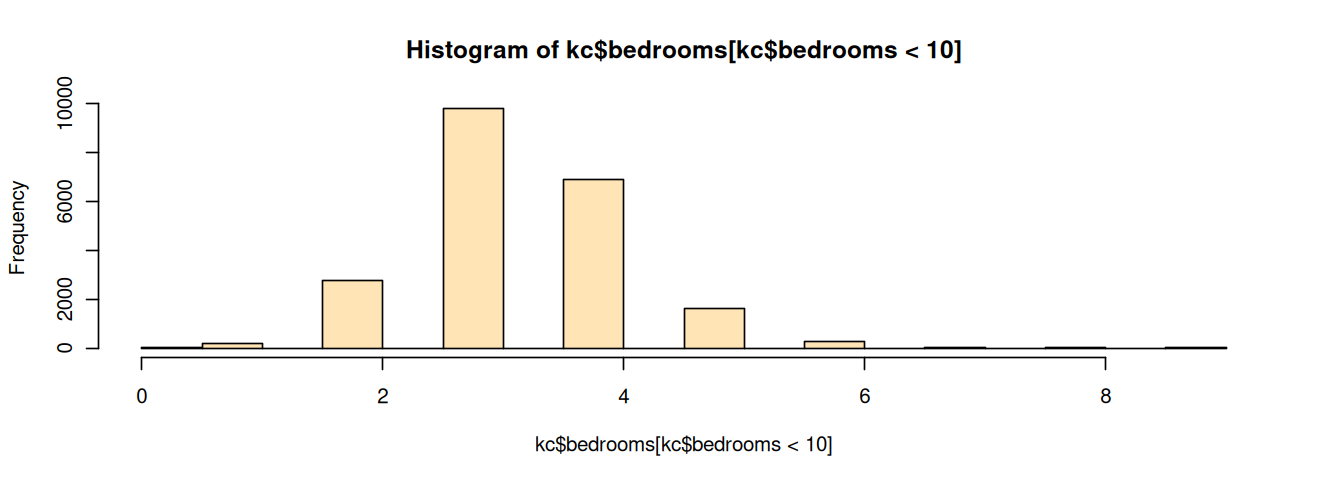

In [64]:
hist(kc$bedrooms[kc$bedrooms<10],col="moccasin")

### Bathrooms

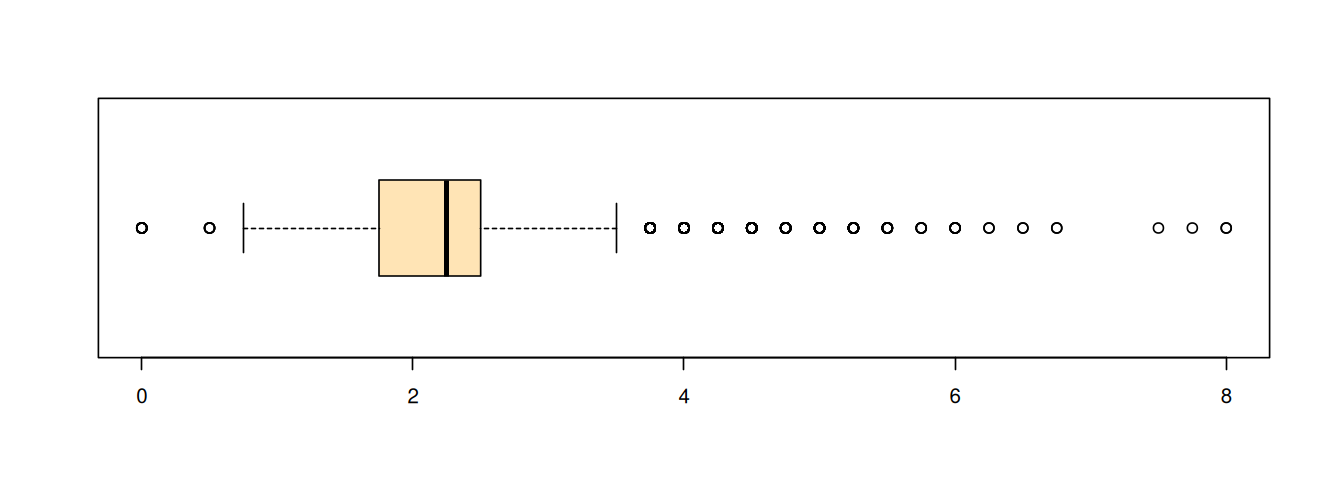

In [65]:
grafdim(11,4)
boxplot(kc$bathrooms, horizontal=TRUE, col="moccasin")

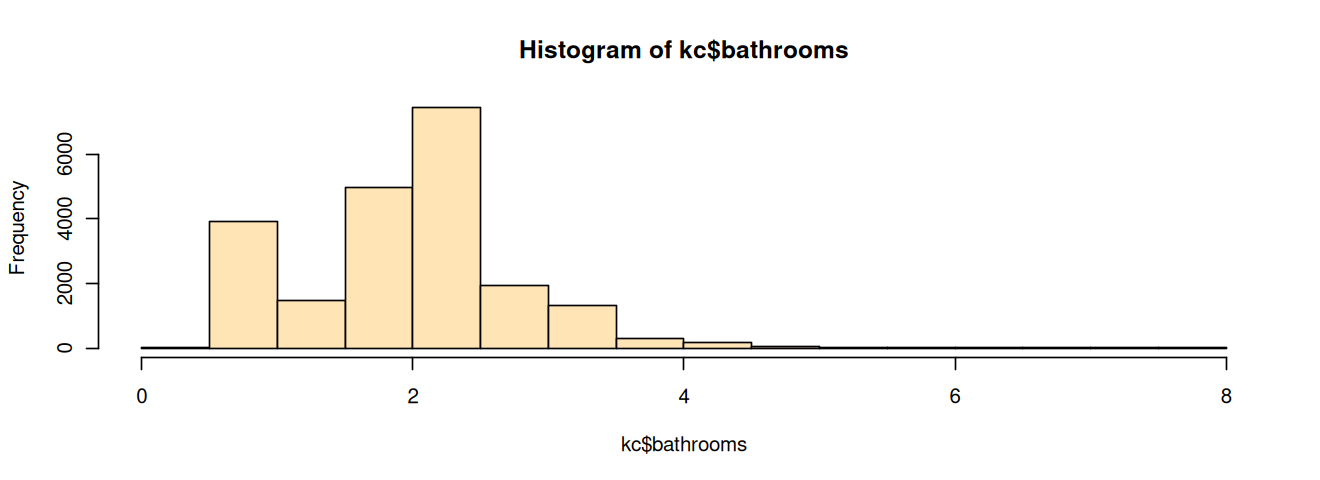

In [66]:
hist(kc$bathrooms,col="moccasin")

### sqft_living

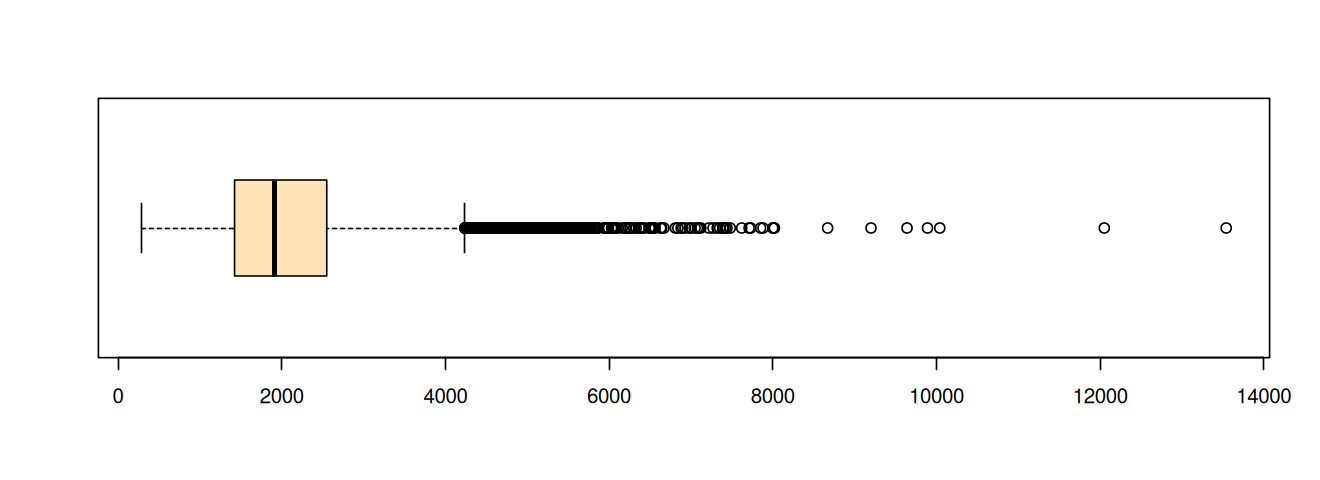

In [67]:
grafdim(11,4)
boxplot(kc$sqft_living, horizontal=TRUE, col="moccasin")

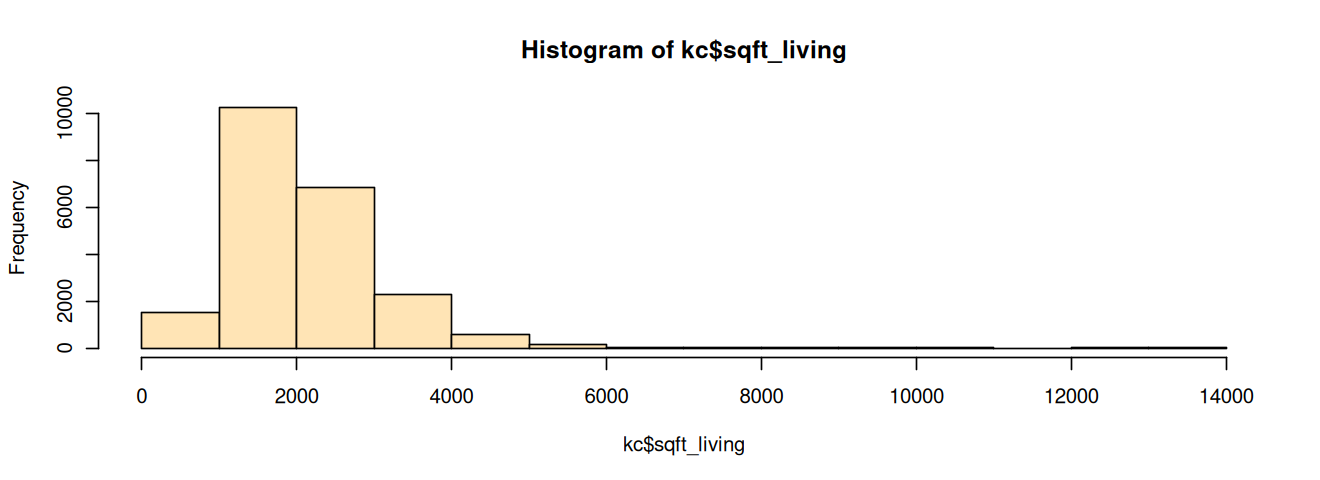

In [68]:
hist(kc$sqft_living,col="moccasin")

In [69]:
kc$living_m2 <- kc$sqft_living * 0.0929

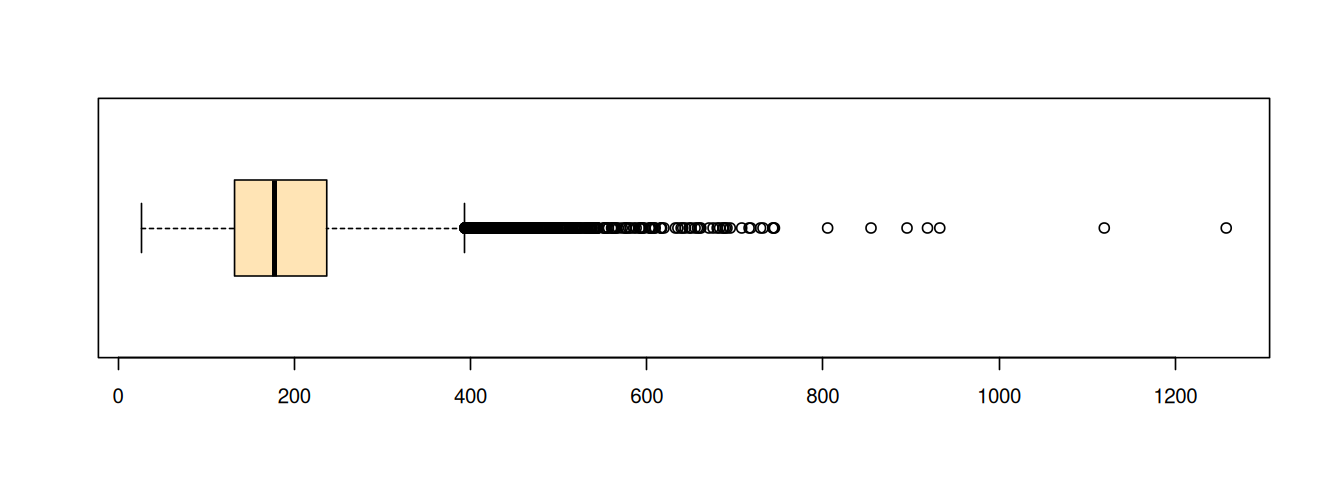

In [70]:
grafdim(11,4)
boxplot(kc$living_m2, horizontal=TRUE, col="moccasin")

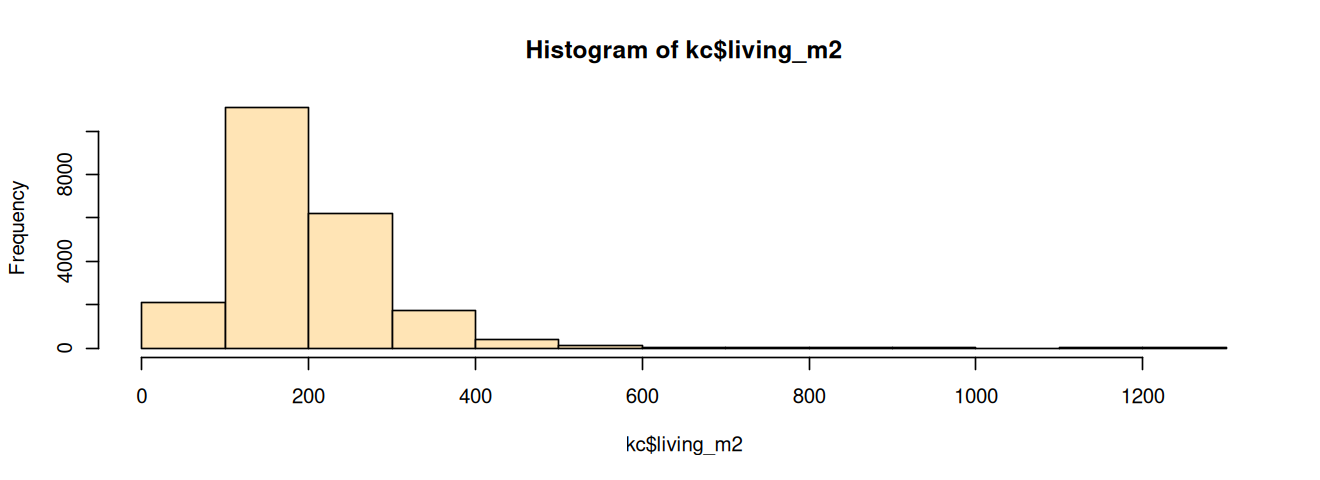

In [71]:
hist(kc$living_m2,col="moccasin")

Salvando os dados para a análise: